# Proyecto Integrador Grupal

Redes Neuronales | Universidad de Palermo

Detección, Segmentación y Estimación de Pose utilizando YOLO26

---

**Grupo 03: Integrantes**
- Aaron Fraga
- Juan Cruz Rey
- Juan Ignacio Pintarelli
- Santiago Minnaar Vizzotto
- Paula Goldenhorn

### Objetivos
- Entrenar un modelo YOLO26 con clases personalizadas.
- Comprender el proceso de recolección y etiquetado de datos.
- Aplicar técnicas de detección de objetos, segmentación y pose estimation.
- Procesar videos utilizando múltiples modelos de visión artificial.
- Generar una salida visual enriquecida con información en tiempo real.
- Integrar distintos modelos de YOLO dentro de una misma solución.

### Requerimientos
1. **Entrenamiento de Nuevas Clases**. Seleccionar entre 2 y 3 clases nuevas que:
    - NO pertenezcan a las 80 clases originales del dataset COCO
    - Sean definidas libremente por el grupo.
2. **Dataset**. El dataset deberá contener al menos:
    - 50 imágenes por cada clase personalizada.
    - Estar correctamente etiquetado.
    - Utilizar formato compatible con YOLO.
3. **Entrenamiento del Modelo**. El entrenamiento deberá realizarse utilizando:
    - Modelos YOLO26.
    - Transfer Learning.
    - Dataset propio generado por el grupo.
    - Deberán documentar:
      - Arquitectura utilizada.
      - Cantidad de épocas.
      - Batch size.
      - Tamaño de imagen.
      - Métricas obtenidas.
      - Resultados del entrenamiento.
4. **Procesamiento de Video**. El sistema desarrollado deberá recibir como entrada:
    - Un video de hasta 2 minutos de duración, o un link de algún video público.
    - Se recomienda preferentemente:
      - 2 o 3 videos cortos de aproximadamente 20 segundos cada uno.
5. **Resultado esperado del Video**. El video procesado deberá integrar simultáneamente:
    - a) **Segmentación**. Mostrar mediante segmentación los objetos pertenecientes al dataset COCO que:
      - Superen un umbral de confianza definido por el grupo.
      - NO incluyan:
        - Personas.
        - Las nuevas clases entrenadas.
        - La segmentación deberá visualizar claramente las regiones detectadas.
    - b) **Estimación de Pose**
      - Las personas detectadas deberán representarse utilizando:
      - Modelo de pose estimation de YOLO.
      - El resultado deberá mostrar:
        - Keypoints.
        - Esqueleto corporal.
        - Seguimiento visual de la pose.
    - c) **Detección de Clases Personalizadas**
      - Las nuevas clases entrenadas deberán visualizarse mediante:
        - Bounding Boxes.
        - Nombre de la clase.
        - Nivel de confianza.
6. **Reporte en Tiempo Real**. El video final deberá incluir un panel o recuadro informativo donde se muestre:
    - Cantidad de objetos detectados por cada clase personalizada (las que ustedes entrenaron nomás).
    - Actualización dinámica durante el procesamiento.
    - Información visible y organizada.
7. **Integración de Modelos**. El proyecto deberá demostrar dentro de una misma solución de procesamiento de video la integración de:
    - YOLO26 Detection
    - YOLO26 Segmentation
    - YOLO26 Pose



# 0. Imports y descarga de herramientas

In [ ]:
# -- Plataforma para usar modelo preentrenado YOLO --
!pip install ultralytics --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 58.3 MB/s eta 0:00:00


In [ ]:
# -- Importación de librerías --
import torch
import urllib.request
import zipfile
import yaml
from ultralytics import YOLO
import time
import os
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import csv
from google.colab.patches import cv2_imshow
from pathlib import Path
import subprocess
from IPython.display import Video, Image, display
from collections import Counter

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
# --- Detección de device ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM total:     {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"VRAM libre:     {torch.cuda.memory_reserved(0) / 1e9:.2f} GB reservada")
    DEVICE_ARG = 0  # índice de GPU para model.train()
else:
    print("⚠️  Sin GPU — el entrenamiento será muy lento, reducir epochs a ≤ 5.")
    DEVICE_ARG = "cpu"

Device: cuda
GPU: Tesla T4
VRAM total:     15.6 GB
VRAM libre:     0.00 GB reservada


# 1. Carga del Dataset

El dataset consta de 459 imágenes etiquetadas en Roboflow con las siguientes clases:
- Barra
- Disco
- Mancuerna

Se recolectaron en mayor proporción imágenes propias tomadas en gimnasios, también se agregaron imágenes de internet y finalmente amplió el dataset con rotaciones y cambios de brillo en las imágenes existentes.

Se dividió el conjunto de datos en:
- 70% para entrenamiento.
- 15% para testeo
- 15% para validación

Se ajustó el tamaño de las imágenes para que todas sean de 768X768

Se aumentó el dataset agregando imágenes que ya existían en el conjunto pero con diferente rotación (entre -10º y 10º) y brillo (entre -12% y 12%).

El dataset fue anotado en Roboflow, una aplicación para etiquetado de imágenes y creación de estructura de directorios para organizar las fotos y utilizarlas con YOLO.

**Carga de dataset (code snippet de Roboflow)**

In [ ]:
!pip install roboflow --quiet

from roboflow import Roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.0/250.0 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 89.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 144.1 MB/s eta 0:00:00


In [ ]:
rf = Roboflow(api_key="TU_ROBOFLOW_API_KEY"  # reemplazar por tu propia API key)
project = rf.workspace("paulas-workspace-clyjk").project("gym-v4lrc")
version = project.version(27)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Gym-27 in yolo26:: 100%|██████████| 923/923 [00:00<00:00, 6154.16it/s]


In [ ]:
# -- Constantes globales --
DATASET_DIR = Path("Gym-27")

CLASS_NAMES = {
    0: "barra",
    1: "disco",
    2: "mancuerna"
}

In [ ]:
# -- Contadar totales --
class_counts = Counter()   # Cantidad de objetos
image_counts = Counter()   # Cantidad de imágenes que contienen la clase

# Contador de imágenes por split
split_image_counts = {}

IMAGE_EXTS = [".jpg", ".jpeg", ".png"]

for split in ["train", "valid", "test"]:

    # =========================
    # Contar imágenes del split
    # =========================
    images_dir = DATASET_DIR / split / "images"

    num_images = sum(
        1
        for f in images_dir.iterdir()
        if f.suffix.lower() in IMAGE_EXTS
    )

    split_image_counts[split] = num_images

    # =========================
    # Contar labels
    # =========================
    labels_dir = DATASET_DIR / split / "labels"

    for txt_file in labels_dir.glob("*.txt"):

        classes_in_image = set()

        with open(txt_file) as f:

            for line in f:

                class_id = int(line.split()[0])

                # Contar objetos individuales
                class_counts[class_id] += 1

                # Guardar clase presente en la imagen
                classes_in_image.add(class_id)

        # Contar imágenes que contienen cada clase
        for class_id in classes_in_image:
            image_counts[class_id] += 1

# ==================================================
# Mostrar cantidad de imágenes por split
# ==================================================
print("Cantidad de IMÁGENES por split:")
print("-" * 35)

total_images = 0

for split, count in split_image_counts.items():
    print(f"{split}: {count} imágenes")
    total_images += count

print("-" * 35)
print(f"TOTAL: {total_images} imágenes")

# ==================================================
# Mostrar cantidad de objetos
# ==================================================
print("\nTotal de OBJETOS de cada clase:")
print("-" * 35)

for class_id, count in class_counts.items():
    print(f"{CLASS_NAMES[class_id]}: {count} objetos")

# ==================================================
# Mostrar cantidad de imágenes por clase
# ==================================================
print("\nTotal de IMÁGENES que contienen cada clase:")
print("-" * 45)

for class_id, count in image_counts.items():
    print(f"{CLASS_NAMES[class_id]}: {count} imágenes")

Cantidad de IMÁGENES por split:
-----------------------------------
train: 402 imágenes
valid: 29 imágenes
test: 28 imágenes
-----------------------------------
TOTAL: 459 imágenes

Total de OBJETOS de cada clase:
-----------------------------------
barra: 757 objetos
disco: 1855 objetos
mancuerna: 1211 objetos

Total de IMÁGENES que contienen cada clase:
---------------------------------------------
barra: 311 imágenes
disco: 253 imágenes
mancuerna: 123 imágenes


**Observación:** El dataset presenta un desbalanceo con respecto a la clase "barra". Esto se debe a que en la mayoría de las imágenes, al ser tomadas en entornos reales de gimnasios, en lugar de fotografiar los elementos individuales se tomaron fotos del espacio en general, donde tendían a aparecer más cantidad de mancuernas y discos que barras. Se puede observar esto en la sección 3. Sin embargo, la cantidad de imágenes que contienen cada clase está más equilibrado.

# 2. Estructura de carpetas

Estructura de directorios que genera Roboflow:
```
dataset_dir/
├── train/
│   ├── images/
│   └── labels/
├── valid/
│   ├── images/
│   └── labels/
└── test/
    ├── images/
    └── labels/
```

In [ ]:
# --- Leer y mostrar formato de un label real ---
label_path = next((DATASET_DIR / "train" / "labels").glob("*.txt"))

print(f"Archivo: {label_path.name}")
print("Contenido (class x_center y_center width height normalizados entre 0–1):")

with open(label_path) as f:

    for linea in f.readlines()[:5]:

        partes = linea.strip().split()

        # Formato YOLO Detection:
        # class x_center y_center width height
        cls = int(partes[0])

        x_center = float(partes[1])
        y_center = float(partes[2])
        width = float(partes[3])
        height = float(partes[4])

        print(
            f"  clase={cls:<3}  "
            f"x_center={x_center:.4f}  "
            f"y_center={y_center:.4f}  "
            f"width={width:.4f}  "
            f"height={height:.4f}"
        )

Archivo: istockphoto-1278398889-612x612_jpg.rf.49847c7c8788fe3d2ac40479099bc04d.txt
Contenido (class x_center y_center width height normalizados entre 0–1):
  clase=0    x_center=0.4030  y_center=0.1660  width=0.4472  height=0.1487
  clase=0    x_center=0.5427  y_center=0.2568  width=1.0000  height=0.2832
  clase=0    x_center=0.5798  y_center=0.3692  width=1.0000  height=0.3936
  clase=0    x_center=0.3974  y_center=0.4652  width=0.9994  height=0.4943
  clase=0    x_center=0.5950  y_center=0.5909  width=0.9932  height=0.6117


# 3. Visualizar Ground Truth segmentations

In [ ]:
CLASS_COLORS = {
    0: (255, 0, 0),    # rojo
    1: (0, 255, 0),    # verde
    2: (0, 0, 255)     # azul
}

def show_sample_roboflow(dataset_dir, split="train", n_images=4):
    """
    Muestra imágenes y su segmentación usando la estructura YOLO de Roboflow.
    """
    img_dir = dataset_dir / split / "images"
    label_dir = dataset_dir / split / "labels"

    image_files = sorted(list(img_dir.glob("*")))[:n_images]

    fig, axes = plt.subplots(1, len(image_files), figsize=(5 * len(image_files), 5))

    if len(image_files) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, image_files):

        # Leer imagen
        img = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        h, w = img.shape[:2]

        # Label correspondiente
        label_path = label_dir / f"{img_path.stem}.txt"

        if label_path.exists():

            with open(label_path, "r") as f:
                lines = f.readlines()

            for line in lines:

                partes = line.strip().split()

                # Clase
                cls = int(partes[0])

                # Coordenadas normalizadas del polígono
                coords = np.array(list(map(float, partes[1:])))

                # Convertir a pares (x,y)
                points = coords.reshape(-1, 2)

                # Escalar a tamaño real de imagen
                points[:, 0] *= w
                points[:, 1] *= h

                points = points.astype(np.int32)

                color = CLASS_COLORS.get(cls, (255, 255, 255))

                # Dibujar polígono
                cv2.polylines(
                    img_rgb,
                    [points],
                    isClosed=True,
                    color=color,
                    thickness=2
                )

                # Texto de clase
                x_text, y_text = points[0]

                cv2.putText(
                    img_rgb,
                    CLASS_NAMES.get(cls, "Unknown"),
                    (x_text, y_text - 10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    color,
                    2
                )

        ax.imshow(img_rgb)
        ax.set_title(img_path.name[:14], fontsize=8)
        ax.axis("off")

    plt.suptitle(f"YOLO Segmentation - Split: {split}", fontsize=12)
    plt.tight_layout()
    plt.show()


show_sample_roboflow(DATASET_DIR, split="train", n_images=3)
show_sample_roboflow(DATASET_DIR, split="valid", n_images=3)
show_sample_roboflow(DATASET_DIR, split="test", n_images=3)

**Observación:** en la primera fila de imágenes, se puede observar la aumentación, donde la misma foto fue duplicada pero con diferencias en su orientación y brillo. En las filas restantes se observa la justificación del desbalanceo de clases con respecto a "barra". Es más probable encontrar mayor cantidad de discos y/o mancuernas que de barras en un entorno real de gimnasio.

# 4. Crear archivo de configuración `data.yaml`

In [ ]:
yaml_path = DATASET_DIR / "data.yaml"

data_dict = {
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val":   "valid/images",
    "test":  "test/images",
    "nc":    3,
    "names": ["barra", "disco", "mancuerna"],
}
with open(yaml_path, "w") as f:
    yaml.dump(data_dict, f, default_flow_style=False, allow_unicode=True)

print(f"Archivo data.yaml creado -> yaml_path: {yaml_path.resolve()}")

Archivo data.yaml creado -> yaml_path: /content/Gym-27/data.yaml


# 5. Fine-Tuning: Entrenamiento de modelos

- Arquitectura utilizada: **YOLO 2026 Nano para Segmentación**
- Cantidad de épocas: **150**
- Tamaño de lote: -1. En el entrenamiento decidió tomar **10** imágenes por batch.
- Tamaño de imagen: **768x768**
- Paciencia: **30**
- Workers: 0
- Optimizador: automático. Decidió usar **AdamW**, con tasa de aprendizaje `lr=0.001429` y `momentum=0.9`
- Copy Paste: **0.3**

> Convergencia en la época 150. Tiempo de entrenamiento ~ 80 mins.

In [ ]:
# -- Parámetros de entrenamiento --
EPOCHS     = 150
BATCH      = -1
IMGSZ      = 768
PATIENCE   = 30
WORKERS    = 0
PROJECT    = "runs/yolo_gym"
RUN_NAME   = "exp_finetune"

yaml_path  = DATASET_DIR / "data.yaml"

# -- Cargar modelo base de segmentación --
model_train = YOLO("yolo26n-seg.pt")

print("Iniciando entrenamiento...")
print(f"  Epochs  : {EPOCHS}")
print(f"  imgsz   : {IMGSZ}")
print(f"  batch   : {BATCH} (auto)")
print(f"  device  : {DEVICE_ARG}")
print(f"  dataset : {yaml_path}")
print()

t0_train = time.perf_counter()

train_results = model_train.train(
    data=str(yaml_path), # Imágenes de entrenamiento

    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=PATIENCE,
    workers=WORKERS,

    device=DEVICE_ARG, # Para usar GPU
    pretrained=True, # Reentrenar modelo YOLO
    cache=True, # Cargar imágenes en caché para acelerar proceso
    augment=True, # Para usar las aumentaciones del dataset
    project=PROJECT,
    name=RUN_NAME,
    verbose=False,

    optimizer="auto",
    copy_paste=0.3 # aumenta el dataset copiando y pegando objetos segmentados
                   # en otras imágenes con una probabilidad del 30%
)

# -- Para calcular el tiempo de entrenamiento --
if device.type == "cuda":
    torch.cuda.synchronize()
tiempo_total = time.perf_counter() - t0_train

print(f"\nEntrenamiento completado en {tiempo_total/60:.1f} min")

RUN_DIR = Path(train_results.save_dir)
print(f"Resultados guardados en: {RUN_DIR}")

Iniciando entrenamiento...
  Epochs  : 150
  imgsz   : 768
  batch   : -1 (auto)
  device  : 0
  dataset : Gym-27/data.yaml

Ultralytics 8.4.66 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Gym-27/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=

## Guardar mejor modelo

In [ ]:
# -- Mejor checkpoint --
best_weights = RUN_DIR / "weights" / "best.pt"
model_best   = YOLO(str(best_weights))

## Curvas de entrenamiento

Para comprender las métricas a continuación, conviene aclarar lo siguiente sobre la tarea que realiza un modelo YOLO para segmentación:
1. Detectar las coordenadas de las cajas (bounding box) donde se encuentran los objetos.
2. Segmentar los objetos con polígonos (la máscara).

Por lo tanto, las métricas se dividen en dos:
- Box (B): métricas sobre detección de bounding boxes.
- Mask (M): métricas sobre segmentación de máscaras.

En este proyecto nos interesan las métricas **Box**, dado que el objetivo de la inferencia será marcar las nuevas clases que aprenderá el modelo con bounding boxes, no polígonos de segmentación.

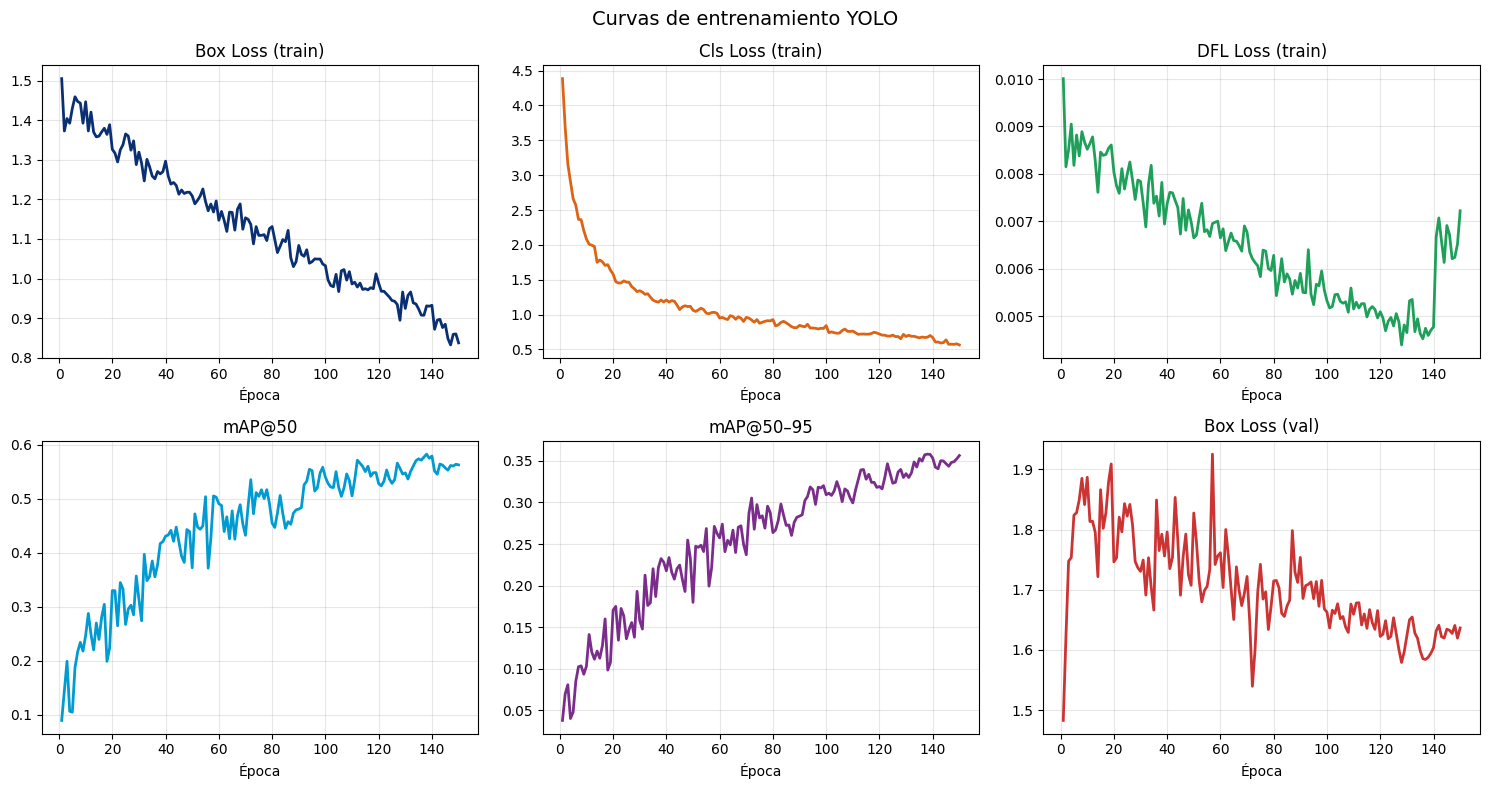

In [ ]:
def plot_training_curves(run_dir):
    """Lee results.csv y grafica pérdidas y métricas."""
    csv_path = Path(run_dir) / "results.csv"
    if not csv_path.exists():
        print(f"No se encontró {csv_path}")
        return

    data = {}
    with open(csv_path) as f:
        reader = csv.DictReader(f)
        for row in reader:
            for key, val in row.items():
                key = key.strip()
                if key not in data:
                    data[key] = []
                try:
                    data[key].append(float(val))
                except ValueError:
                    pass

    epochs = data.get("epoch", list(range(len(next(iter(data.values()))))))

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))

    plots = [
        ("train/box_loss",  "Box Loss (train)",    axes[0, 0], "#0a3073"),
        ("train/cls_loss",  "Cls Loss (train)",    axes[0, 1], "#dc6414"),
        ("train/dfl_loss",  "DFL Loss (train)",    axes[0, 2], "#1ea05a"),
        ("metrics/mAP50(B)",   "mAP@50",              axes[1, 0], "#009bd2"),
        ("metrics/mAP50-95(B)","mAP@50–95",           axes[1, 1], "#7b2d8b"),
        ("val/box_loss",    "Box Loss (val)",      axes[1, 2], "#cc3333"),
    ]

    for col_name, title, ax, color in plots:
        vals = data.get(col_name, [])
        if vals:
            ax.plot(epochs[:len(vals)], vals, color=color, linewidth=2)
            ax.set_title(title)
            ax.set_xlabel("Época")
            ax.grid(True, alpha=0.3)
        else:
            ax.text(0.5, 0.5, f"{col_name}\nno disponible",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_title(title)

    plt.suptitle("Curvas de entrenamiento YOLO", fontsize=14)
    plt.tight_layout()
    plt.show()

plot_training_curves(RUN_DIR)

**Observación**: consistentemente, la pérdida fue reduciéndose y el mAP de los Bounding Box fue subiendo (aunque con altibajos).

## Galería de resultados

In [ ]:
def show_run_gallery(run_dir, patrones=["results.png"], max_images=9):
    """Muestra las imágenes de diagnóstico que YOLO genera automáticamente."""
    run_dir = Path(run_dir)
    imagenes = [run_dir / p for p in patrones if (run_dir / p).exists()]

    if not imagenes:
        print("No se encontraron imágenes de diagnóstico.")
        return

    n = min(len(imagenes), max_images)
    cols = min(n, 3)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 5 * rows))
    if n == 1:
        axes = [[axes]]
    elif rows == 1:
        axes = [axes]

    for i, img_path in enumerate(imagenes[:n]):
        row, col = divmod(i, cols)
        ax = axes[row][col]
        ax.imshow(plt.imread(img_path))
        ax.set_title(img_path.name, fontsize=9)
        ax.axis("off")

    # Ocultar ejes vacíos
    for i in range(n, rows * cols):
        row, col = divmod(i, cols)
        axes[row][col].axis("off")

    plt.suptitle("Galería de resultados del run", fontsize=13)
    plt.tight_layout()
    plt.show()

patrones = [
    "train_batch0.jpg",
    "train_batch1.jpg",
    "train_batch2.jpg",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
]
show_run_gallery(RUN_DIR, patrones)

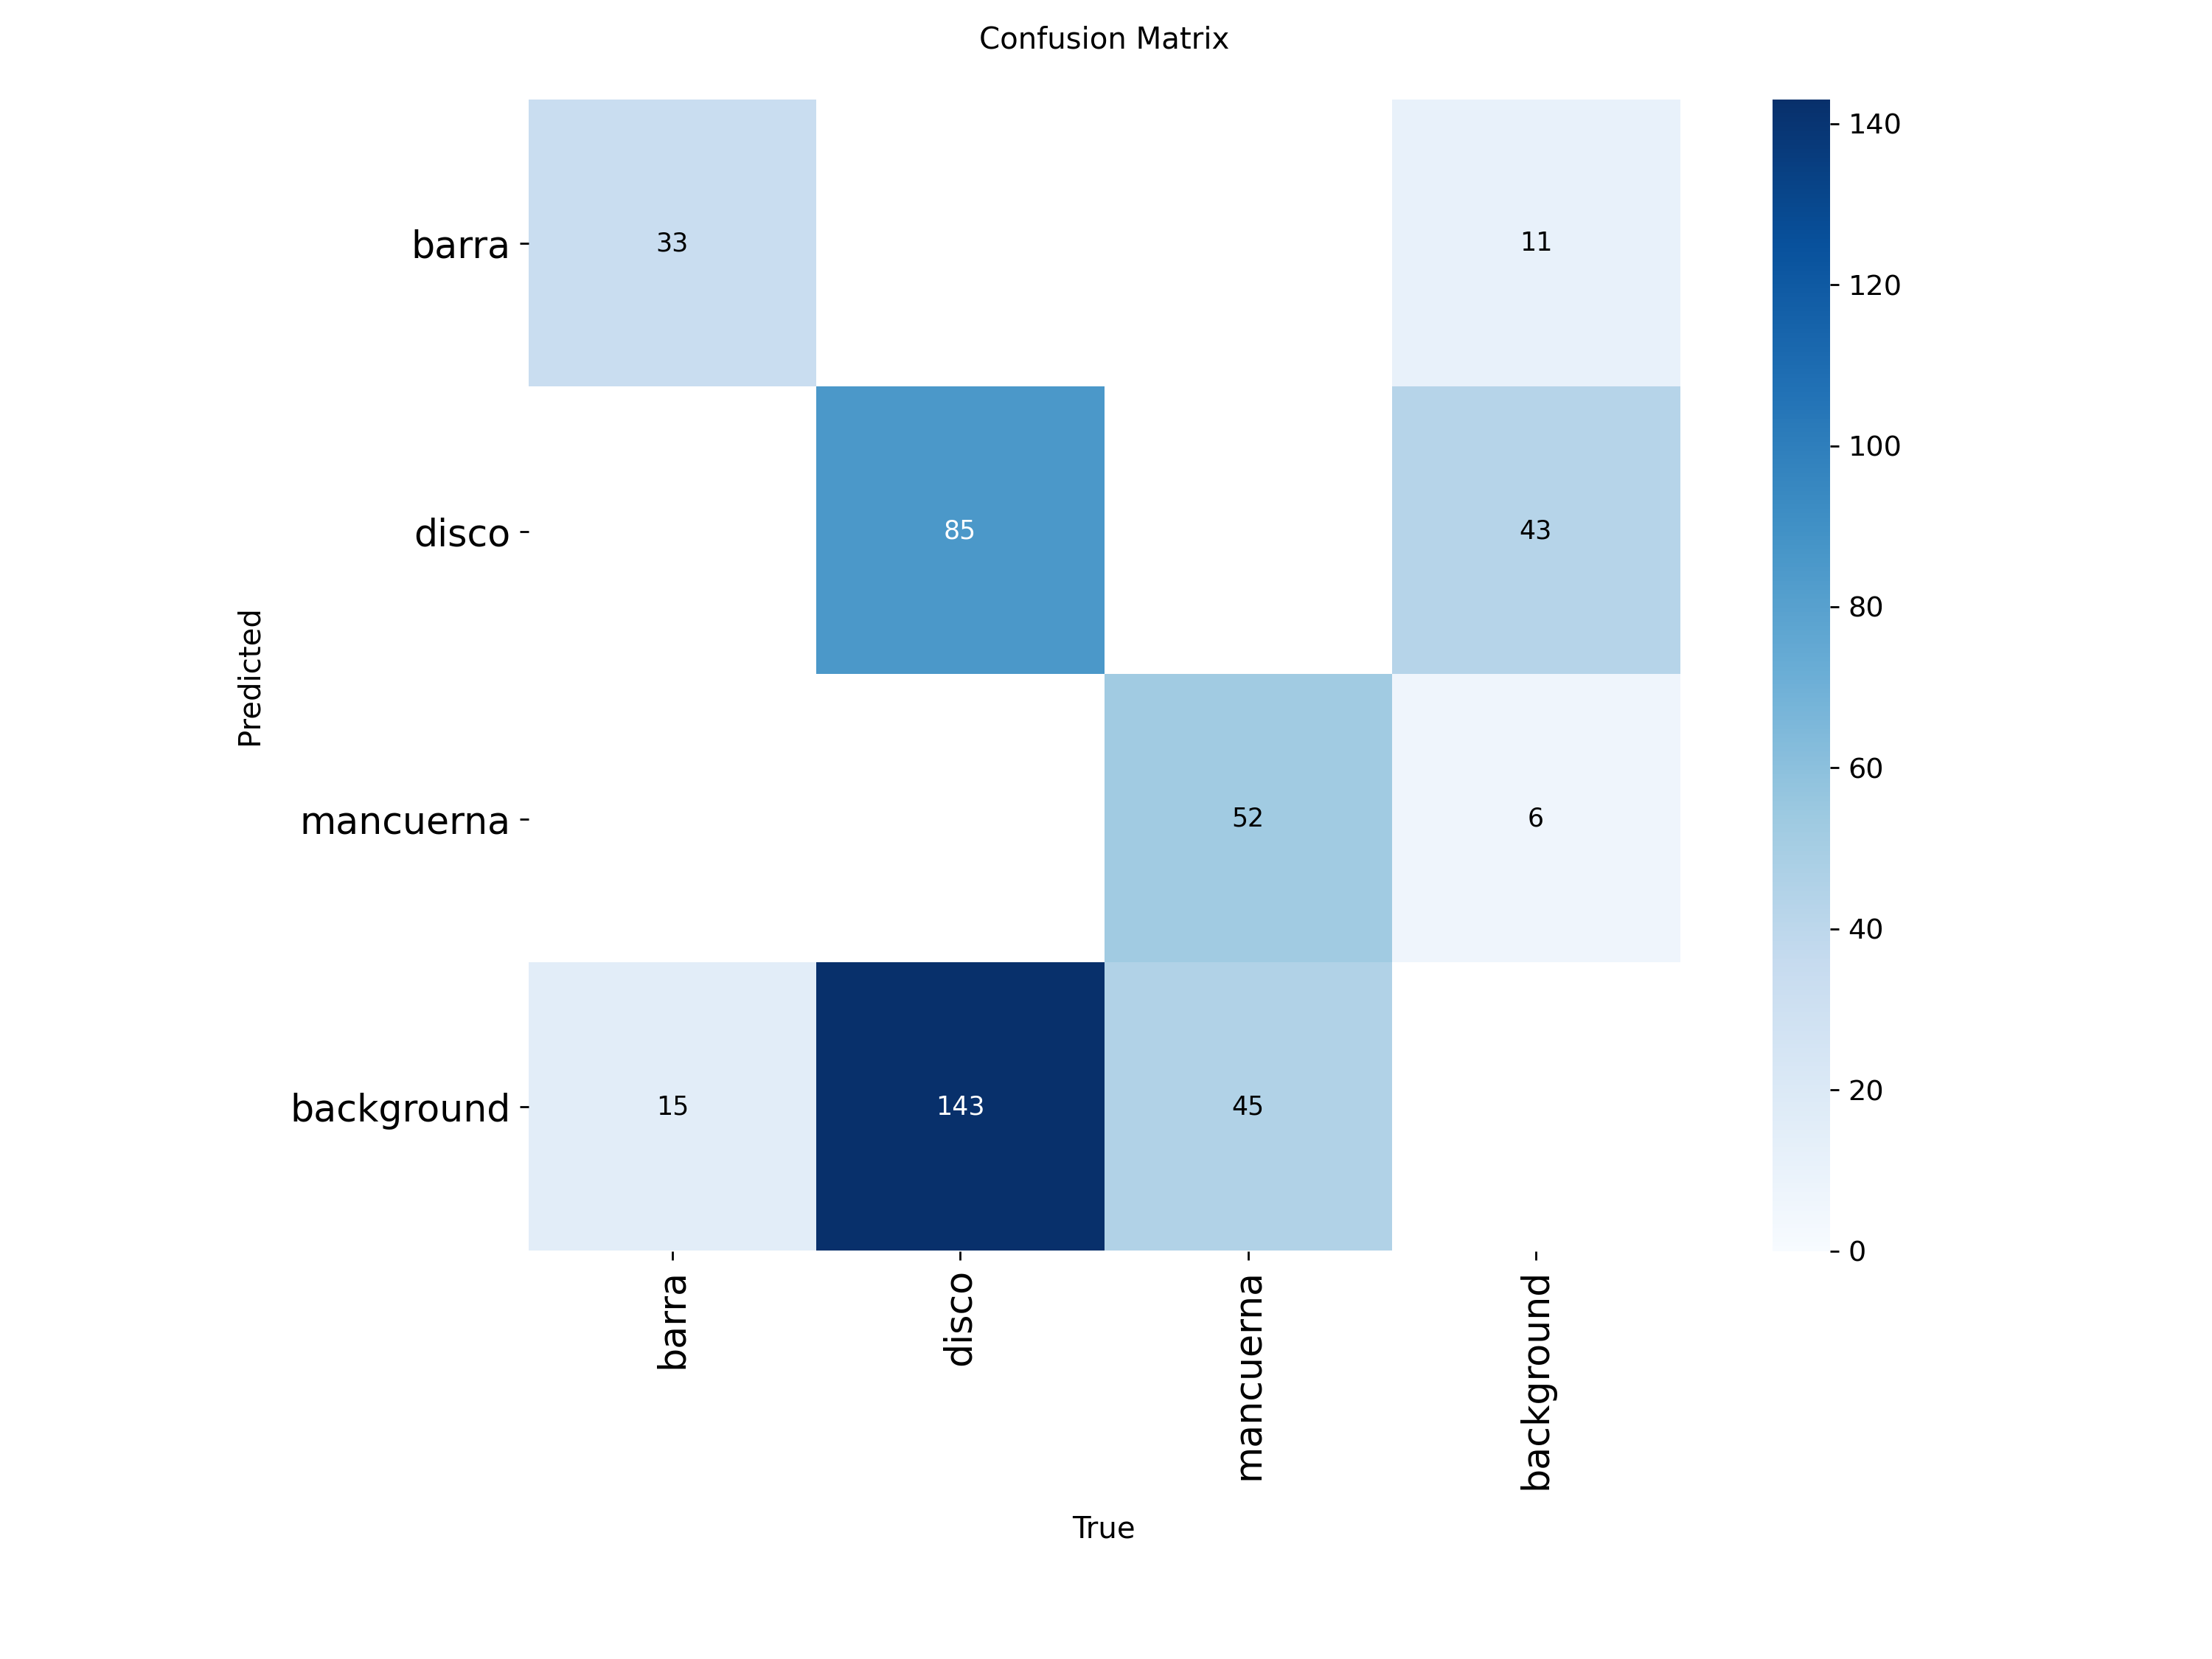

In [ ]:
imagen = RUN_DIR/"confusion_matrix.png"
display(Image(filename=imagen))

**Insights:** la matriz de confusión muestra que existe una separación prácticamente perfecta entre las tres clases de objetos, ya que casi no se observan confusiones entre barra, disco y mancuerna. Los errores del modelo vienen principalmente de objetos reales que son clasificados como fondo (background), especialmente en la clase disco. Con ello podemos inferir que los objetos no siempre se encuentran claros y fáciles de detectar, lo cual es lógico porque en un gimnasio las mancuernas, barras y discos suelen estar superpuestas, parcialmente ocultos por otros objetos, la iluminación no es la adecuada para diferenciarlos correctamente o están muy chiquitos en la imagen.

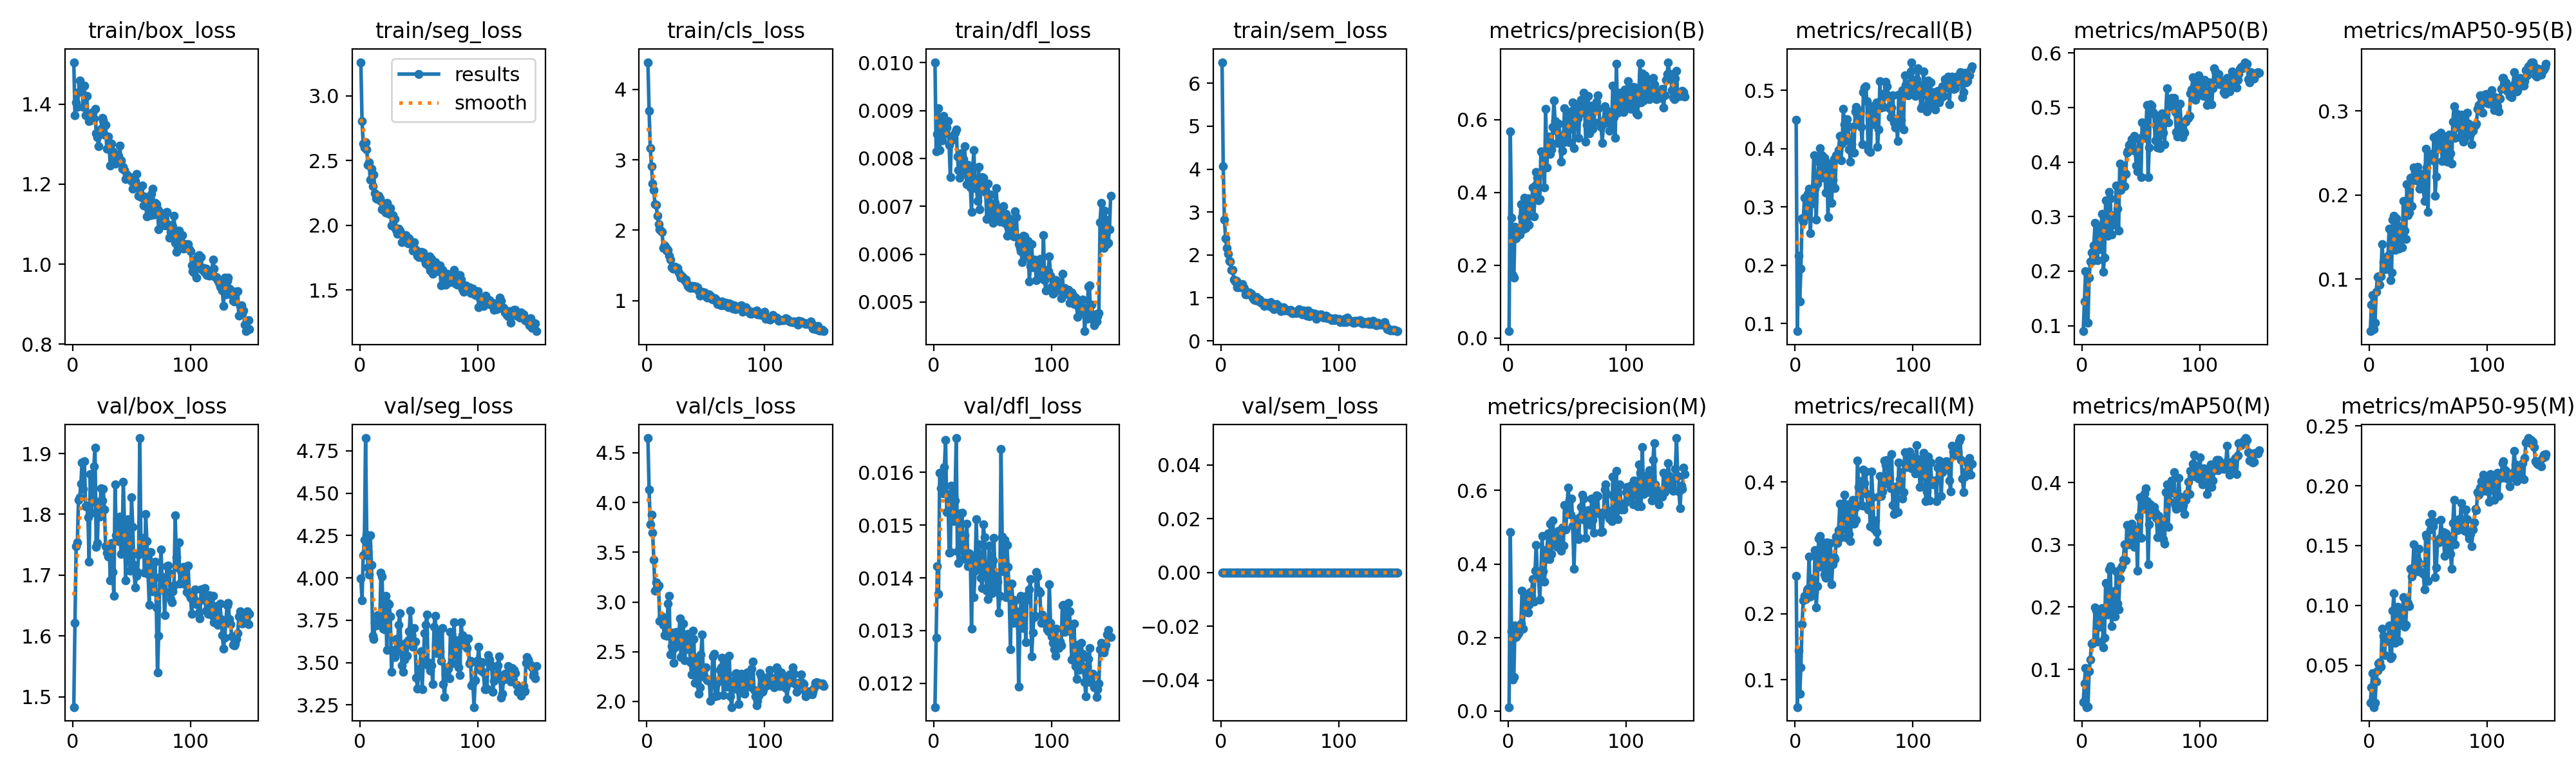

In [ ]:
imagen = RUN_DIR/"results.png"
display(Image(filename=imagen))


**Insights**: Todas las pérdidas de entrenamiento (`box_loss, seg_loss, cls_loss, sem_loss`) descienden de forma sostenida durante las 150 épocas.
Las pérdidas de validación también muestran una tendencia descendente general, aunque con más ruido (lo cual es normal porque sólo se tienen 29 imágenes de validación, contra 402 en entrenamiento). La Precision, Recall, mAP50 y mAP50-95 siguen creciendo hasta el final del entrenamiento tanto para la tarea de detección (B) como de segmentación (M). No parece haber sobreajuste, si lo hubiera, las pérdidas de validación subirían cuando las de entrenamiento siguen bajando.

# 4. Evaluación

## Testeo

Para la inferencia, elegimos un umbral de confianza de **0.25**

### Inferencia sobre dataset de test

In [ ]:
# -- Predicción sobre imágenes de test --
test_images = sorted(
    (DATASET_DIR / "test" / "images").glob("*")
)[:15]

# Predicciones
pred_results = model_best.predict(
    source=[str(p) for p in test_images],
    conf=0.25,
    device=DEVICE_ARG,
    verbose=False
)

# ==========================================
# Crear grilla dinámica
# ==========================================
n_imgs = len(pred_results)

cols = 3
rows = math.ceil(n_imgs / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))

axes = axes.flatten()

# ==========================================
# Mostrar resultados
# ==========================================
for ax, res in zip(axes, pred_results):

    plotted = res.plot()

    # BGR -> RGB
    ax.imshow(plotted[:, :, ::-1])

    n_det = len(res.boxes) if res.boxes is not None else 0

    ax.set_title(f"{n_det} detecciones", fontsize=9)

    ax.axis("off")

# Ocultar ejes sobrantes
for ax in axes[len(pred_results):]:
    ax.axis("off")

plt.suptitle("Predicciones sobre imágenes de test", fontsize=13)

plt.tight_layout()

plt.show()

**Observación:** las clases "disco" y "mancuerna" parecen en su mayoría bien detectadas. Sin embargo, el modelo comete algunos errores en detectar a "barra", en algunas imágenes no detecta el objeto, en otras solo crea una caja en una parte de la barra, y en otras dice que es barra cuando en realidad no lo es (observar la primera imagen donde los reflejos de luz sobre los estantes negros confunden al modelo con que eso es una barra). De todas formas, esta es solo una muestra, es más preciso analizar la matriz de confusión.

### Inferencia sobre imágen propia

WARNING ⚠️ Model does not support 'augment=True', reverting to single-scale prediction.


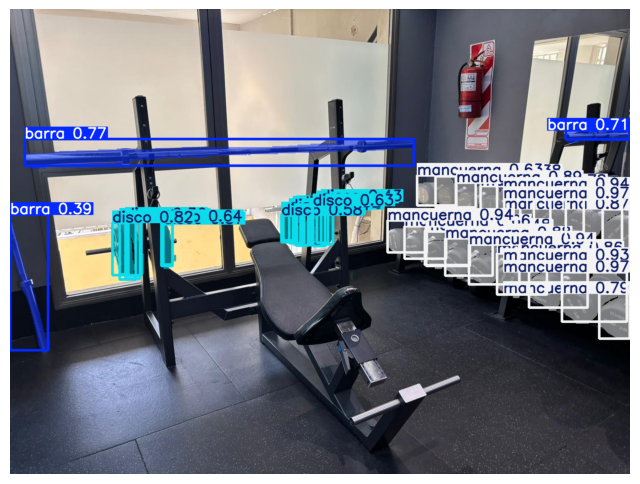

In [ ]:
# -- Predicciones --
pred_results = model_best.predict(
    source="/content/press.jpeg",
    conf=0.25,
    device=DEVICE_ARG,
    verbose=False,
)

# Primer resultado
res = pred_results[0]

# Dibujar detecciones
img = res.plot()

# Mostrar
plt.figure(figsize=(8,8))
plt.imshow(img[:, :, ::-1])  # BGR -> RGB
plt.axis("off")
plt.show()

**Nota**: Aquí la detección es muy prometedora, de hecho se observa que el modelo pudo encontrar la barra de la izquierda apoyada en el piso (con una confianza del 39%) y también el pedacito de barra que aparece en el lado derecho en el espejo (con una confianza del 71%).

## Validación

Calculamos las métricas sobre el dataset de validación

In [ ]:
# -- Métricas sobre imágenes de validación --
val_results = model_best.val(
    data=str(yaml_path),
    device=DEVICE_ARG,
    verbose=False
)

print()
print("=== Métricas de validación ===")
print(f"  mAP@50      : {val_results.box.map50:.4f}")
print(f"  mAP@50–95   : {val_results.box.map:.4f}")
print(f"  Precisión   : {val_results.box.mp:.4f}")
print(f"  Recall      : {val_results.box.mr:.4f}")

Ultralytics 8.4.66 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2708.5±911.9 MB/s, size: 76.8 KB)
val: Scanning /content/Gym-27/valid/labels.cache... 29 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 29/29 11.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1s/it 2.2s
                   all         29        373      0.718      0.516      0.575      0.356       0.64      0.454      0.467      0.238
Speed: 8.9ms preprocess, 10.5ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/runs/segment/val-2

=== Métricas de validación ===
  mAP@50      : 0.5748
  mAP@50–95   : 0.3557
  Precisión   : 0.7179
  Recall      : 0.5157


**Insights:** La precisión es bastante buena, lo que indica que la mayoría de las detecciones realizadas por el modelo son correctas, pero el recall es considerablemente menor, evidenciando una tendencia a cometer Errores Tipo II o Falsos Negativos. Esto quiere decir que el modelo no detecta todos los objetos presentes en las imágenes, si no que es más conservador al realizar predicciones.
> Cuando detecta un objeto suele acertar, pero deja pasar muchas instancias reales.


In [ ]:
print("mAP@50-95 por clase")
for i, ap in enumerate(val_results.box.maps):
    print(f"{val_results.names[i]}: {ap:.4f}")

mAP@50-95 por clase
barra: 0.3815
disco: 0.2706
mancuerna: 0.4150


**Insights:** Observando el AP por clase, se confirma que disco es la clase más difícil para el modelo, obteniendo el menor desempeño. Esto coincide con lo observado en la matriz de confusión, donde una gran cantidad de discos reales no fueron detectados y fueron clasificados como fondo (background). Por otro lado, mancuerna tiene el mejor rendimiento, mientras que barra está en el medio a pesar de contar con una menor cantidad de instancias etiquetadas en el conjunto de entrenamiento.

# 5. Exportar mejor modelo

In [ ]:
# ONNX — compatible con cualquier plataforma
export_onnx = model_best.export(
    format="onnx",
    opset=17,
    dynamic=True,
    imgsz=IMGSZ,
)
print(f"ONNX exportado: {export_onnx}")

Ultralytics 8.4.66 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/content/runs/segment/runs/yolo_gym/exp_finetune-2/weights/best.pt' with input shape (1, 3, 768, 768) BCHW and output shape(s) ((1, 300, 38), (1, 32, 192, 192)) (6.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 232ms
Prepared 4 packages in 1.93s
Installed 4 packages in 359ms
 + colorama==0.4.6
 + onnx==1.21.0
 + onnxruntime==1.26.0
 + onnxslim==0.1.94

requirements: AutoUpdate success ✅ 3.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.21.0 opset 17...


Exporting aten::index operator of advanced indexing in opset 17 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.


ONNX: slimming with onnxslim 0.1.94...
ONNX: export success ✅ 8.7s, saved as '/content/runs/segment/runs/yolo_gym/exp_finetune-2/weights/best.onnx' (11.0 MB)

Export complete (9.3s)
Results saved to /content/runs/segment/runs/yolo_gym/exp_finetune-2/weights/best.onnx
Predict:         yolo predict task=segment model=/content/runs/segment/runs/yolo_gym/exp_finetune-2/weights/best.onnx imgsz=768 
Validate:        yolo val task=segment model=/content/runs/segment/runs/yolo_gym/exp_finetune-2/weights/best.onnx imgsz=768 data=Gym-27/data.yaml  
Visualize:       https://netron.app
ONNX exportado: /content/runs/segment/runs/yolo_gym/exp_finetune-2/weights/best.onnx


# Conclusión de la evaluación

- En términos generales, el modelo alcanzó un desempeño satisfactorio para un dataset como este que es pequeño y, además, empleando una arquitectura liviana (Nano).
- Las curvas de entrenamiento y validación muestran una convergencia estable, sin evidencias claras de sobreajuste, ya que las pérdidas disminuyen progresivamente mientras que las métricas de precisión, recall y mAP continúan mejorando a lo largo de las épocas.
- La precisión obtenida (0.72) indica que la mayoría de las detecciones realizadas son correctas, aunque el recall (0.52) evidencia que todavía existe una cantidad considerable de objetos no detectados. Esto también se refleja en la matriz de confusión, donde los errores predominantes corresponden a falsos negativos, especialmente en la clase disco.
- En conjunto, los resultados indican que el modelo logró aprender correctamente las características visuales de las clases objetivo, en especial nos parece relevante destacar que el modelo logró aprender a individualizar los objetos, es decir, no confunde una barra de una mancuerna ni de un disco. Esto se debe a que las formas y tamaños de los objetos son claramente diferentes.